# Projeto Aplicado I — Planejamento de Manutenções no Metrô de São Paulo

## Objetivo do projeto

Este projeto tem como objetivo analisar dados públicos do Metrô de São Paulo para identificar padrões na demanda de passageiros, na oferta de trens e na infraestrutura do sistema metroviário.

A análise busca compreender como essas informações podem contribuir para o planejamento das atividades de manutenção, considerando a importância de reduzir os impactos sobre os passageiros.

## Etapas da análise

O notebook está organizado em etapas que incluem a importação das bibliotecas, o carregamento e a preparação dos dados, a análise da demanda de passageiros, a comparação entre estações, a análise dos intervalos entre trens e a interpretação dos resultados.

## 1. Importação e inspeção inicial dos dados

Nesta etapa, são importadas as bibliotecas necessárias e carregado um arquivo para verificar sua estrutura. Também são consultados os nomes das colunas, os tipos de dados, os valores ausentes, as linhas duplicadas e as estatísticas descritivas.

In [322]:
import pandas as pd
from google.colab import files

arquivos = files.upload()
nome_arquivo = list(arquivos.keys())[0]

df = pd.read_csv(
    nome_arquivo,
    sep=None,
    engine="python",
    encoding="cp1252"
)

df.head()

Saving Entrada de Passageiros por Linha  - 2025_8.csv to Entrada de Passageiros por Linha  - 2025_8 (9).csv


,METRÔ DE SÃO PAULO,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
4,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX


In [323]:
print("Nomes das colunas:")
print(df.columns.tolist())

print("\nInformações do arquivo:")
df.info()

Nomes das colunas:
['METRÔ DE SÃO PAULO', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']

Informações do arquivo:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   METRÔ DE SÃO PAULO  53 non-null     object 
 1   Unnamed: 1          42 non-null     object 
 2   Unnamed: 2          42 non-null     object 
 3   Unnamed: 3          42 non-null     object 
 4   Unnamed: 4          42 non-null     object 
 5   Unnamed: 5          42 non-null     object 
 6   Unnamed: 6          0 non-null      float64
 7   Unnamed: 7          30 non-null     object 
 8   Unnamed: 8          28 non-null     object 
 9   Unnamed: 9          28 non-null     object 
 10  Unnamed: 10         28 non-null     object 
 11  Unnamed: 11      

In [324]:
df.isnull().sum()

,0
METRÔ DE SÃO PAULO,5
Unnamed: 1,16
Unnamed: 2,16
Unnamed: 3,16
Unnamed: 4,16
Unnamed: 5,16
Unnamed: 6,58
Unnamed: 7,28
Unnamed: 8,30
Unnamed: 9,30


In [325]:
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 5


In [326]:
df.describe(include="all")

,METRÔ DE SÃO PAULO,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
count,53,42,42,42,42,42,0.0,30,28,28,28,28,28
unique,25,40,36,33,36,37,NaN,16,27,22,18,20,17
top,Jan,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,85,46,24,581
freq,3,3,3,3,3,3,NaN,2,2,3,5,7,3
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [327]:
print(df.columns.tolist())
print(df.head(5))

['METRÔ DE SÃO PAULO', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']
                               METRÔ DE SÃO PAULO Unnamed: 1 Unnamed: 2  \
0              INFORMAÇÕES SOBRE A DEMANDA - 2025        NaN        NaN   
1  Entrada de Passageiros por Linha (em milhares)        NaN        NaN   
2                                             NaN        NaN        NaN   
3                                  LINHA 1-AZUL ¹        NaN        NaN   
4                                             Mês      Total        MDU   

  Unnamed: 3 Unnamed: 4 Unnamed: 5  Unnamed: 6       Unnamed: 7 Unnamed: 8  \
0        NaN        NaN        NaN         NaN              NaN        NaN   
1        NaN        NaN        NaN         NaN              NaN        NaN   
2        NaN        NaN        NaN         NaN              NaN        NaN   
3        NaN        NaN        NaN         

In [328]:
print("Colunas de df:")
print(df.columns.tolist())

print("\nPrimeiras linhas:")
display(df.head(10))

Colunas de df:
['METRÔ DE SÃO PAULO', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']

Primeiras linhas:


,METRÔ DE SÃO PAULO,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
4,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,18.128,695,439,250,745,NaN,Jan,11.528,455,218,144,506
6,Fev,19.001,807,457,258,840,NaN,Fev,12.511,542,260,156,584
7,Mar,20.116,832,489,272,860,NaN,Mar,12.965,556,262,164,581
8,Abr,20.400,843,475,260,872,NaN,Abr,13.170,561,245,158,585
9,Mai,20.962,827,484,266,858,NaN,Mai,13.507,555,248,155,581


## 2. Exploração e preparação dos dados de passageiros

Nesta etapa, o arquivo é lido considerando sua estrutura original. A tabela é explorada para localizar os dados das Linhas 1-Azul e 2-Verde, identificar os cabeçalhos e organizar os valores mensais para análise.

In [329]:
df = pd.read_csv(nome_arquivo, sep=";", encoding="latin1", header=None)

display(df.iloc[3:12, :13])

,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
5,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX
6,Jan,18.128,695,439,250,745,NaN,Jan,11.528,455,218,144,506
7,Fev,19.001,807,457,258,840,NaN,Fev,12.511,542,260,156,584
8,Mar,20.116,832,489,272,860,NaN,Mar,12.965,556,262,164,581
9,Abr,20.400,843,475,260,872,NaN,Abr,13.170,561,245,158,585
10,Mai,20.962,827,484,266,858,NaN,Mai,13.507,555,248,155,581
11,Jun,19.276,794,471,262,832,NaN,Jun,12.352,528,248,159,564


In [330]:
# Tratamento da Linha 2 - Verde
verde = df.iloc[5:18, 7:13].copy()

verde.columns = verde.iloc[0].astype(str).str.strip()
verde = verde.iloc[1:].copy()

verde = verde.reset_index(drop=True)

# Remover linhas sem mês
verde = verde[verde.iloc[:, 0].notna()]

# Converter os valores numéricos
for coluna in ["Total", "MDU", "MSA", "MDO", "MAX"]:
    verde[coluna] = (
        verde[coluna]
        .astype(str)
        .str.replace(".", "", regex=False)
    )
    verde[coluna] = pd.to_numeric(verde[coluna], errors="coerce")

verde

5,Mês,Total,MDU,MSA,MDO,MAX
0,Jan,11528,455,218,144,506
1,Fev,12511,542,260,156,584
2,Mar,12965,556,262,164,581
3,Abr,13170,561,245,158,585
4,Mai,13507,555,248,155,581
5,Jun,12352,528,248,159,564
6,Jul,12583,491,243,151,517
7,Ago,13354,540,249,154,576
8,Set,13784,547,253,183,570
9,Out,13993,540,242,153,564


In [331]:
print("Colunas de azul:")
print(azul.columns.tolist())

print("\nPrimeiras linhas de azul:")
display(azul.head())

Colunas de azul:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Primeiras linhas de azul:


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,METRÔ DE SÃO PAULO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN


In [335]:

# Organizar os dados mensais das Linhas Azul e Verde

azul = df_linhas.iloc[5:17, 0:6].copy()
azul.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

verde = df_linhas.iloc[5:17, 7:13].copy()
verde.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

for tabela in [azul, verde]:
    tabela["Mês"] = tabela["Mês"].astype(str).str.strip()
    tabela["Total"] = (
        tabela["Total"].astype(str)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    tabela["Total"] = pd.to_numeric(tabela["Total"], errors="coerce")

display(azul.head())
display(verde.head())


,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,18128,695,439,250,745
6,Fev,19001,807,457,258,840
7,Mar,20116,832,489,272,860
8,Abr,20400,843,475,260,872
9,Mai,20962,827,484,266,858


,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,11528,455,218,144,506
6,Fev,12511,542,260,156,584
7,Mar,12965,556,262,164,581
8,Abr,13170,561,245,158,585
9,Mai,13507,555,248,155,581


In [336]:
print(azul[["Mês", "Total"]].to_string(index=False))

Mês  Total
Jan  18128
Fev  19001
Mar  20116
Abr  20400
Mai  20962
Jun  19276
Jul  19428
Ago  20548
Set  21052
Out  21644
Nov  19870
Dez  18818


In [337]:
azul = azul[azul["Mês"].isin([
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
])].copy()

print(azul[["Mês", "Total"]].to_string(index=False))

Mês  Total
Jan  18128
Fev  19001
Mar  20116
Abr  20400
Mai  20962
Jun  19276
Jul  19428
Ago  20548
Set  21052
Out  21644
Nov  19870
Dez  18818


In [338]:
print(df.iloc[5, 0:6].tolist())

['Mês', 'Total', 'MDU', 'MSA', 'MDO', 'MAX']


In [339]:
display(df.iloc[3:8, 0:6])

,0,1,2,3,4,5
3,NaN,NaN,NaN,NaN,NaN,NaN
4,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN
5,Mês,Total,MDU,MSA,MDO,MAX
6,Jan,18.128,695,439,250,745
7,Fev,19.001,807,457,258,840


In [340]:
janeiro = pd.DataFrame([{
    "Mês": "Jan",
    "Total": 18128,
    "MDU": 695,
    "MSA": 439,
    "MDO": 250,
    "MAX": 745
}])

azul = pd.concat([janeiro, azul], ignore_index=True)

display(azul[["Mês", "Total"]])

,Mês,Total
0,Jan,18128
1,Jan,18128
2,Fev,19001
3,Mar,20116
4,Abr,20400
5,Mai,20962
6,Jun,19276
7,Jul,19428
8,Ago,20548
9,Set,21052


In [341]:
print(azul.columns.tolist())
print(verde.columns.tolist())
print(azul.shape, verde.shape)

['Mês', 'Total', 'MDU', 'MSA', 'MDO', 'MAX']
['Mês', 'Total', 'MDU', 'MSA', 'MDO', 'MAX']
(13, 6) (12, 6)


In [342]:
print([v for v in globals() if "azul" in v.lower() or "linha" in v.lower()])

['azul', 'azul_grafico', 'linha', 'linhas', 'arquivo_linhas', 'df_linhas', 'media_azul', 'top10_azul', 'azul_estacoes']


In [343]:
print(type(linhas))

if isinstance(linhas, dict):
    print(linhas.keys())
elif isinstance(linhas, pd.DataFrame):
    print(linhas.columns.tolist())
    display(linhas.head())

<class 'list'>


In [344]:
print(len(linhas))

for i, item in enumerate(linhas):
    print(i, type(item))
    if isinstance(item, pd.DataFrame):
        print(item.columns.tolist())
        display(item.head(3))
    else:
        print(item)

4
0 <class 'str'>
Linha 1-Azul
1 <class 'str'>
Linha 2-Verde
2 <class 'str'>
Linha 3-Vermelha
3 <class 'str'>
Linha 15-Prata


In [345]:
print([v for v in globals() if "df" in v.lower() or "arquivo" in v.lower()])

['arquivo', 'arquivos', 'nome_arquivo', 'df', 'arquivos_oferta', 'arquivo_oferta', 'arquivo_linhas', 'df_linhas']


In [346]:
print(type(df))
print(df.shape)
display(df.head(10))

<class 'pandas.core.frame.DataFrame'>
(59, 13)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,METRÔ DE SÃO PAULO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
5,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX
6,Jan,18.128,695,439,250,745,NaN,Jan,11.528,455,218,144,506
7,Fev,19.001,807,457,258,840,NaN,Fev,12.511,542,260,156,584
8,Mar,20.116,832,489,272,860,NaN,Mar,12.965,556,262,164,581
9,Abr,20.400,843,475,260,872,NaN,Abr,13.170,561,245,158,585


In [347]:
print(df.columns.tolist())

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [348]:
display(df.iloc[:10, :25])

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,METRÔ DE SÃO PAULO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
5,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX
6,Jan,18.128,695,439,250,745,NaN,Jan,11.528,455,218,144,506
7,Fev,19.001,807,457,258,840,NaN,Fev,12.511,542,260,156,584
8,Mar,20.116,832,489,272,860,NaN,Mar,12.965,556,262,164,581
9,Abr,20.400,843,475,260,872,NaN,Abr,13.170,561,245,158,585


In [349]:
print(arquivos.keys() if isinstance(arquivos, dict) else arquivos)

dict_keys(['Entrada de Passageiros por Linha  - 2025_8 (9).csv'])


In [350]:
import os

print(os.listdir())

['.config', 'Entrada de Passageiros por Estação - Diária - 2025_7 (3).csv', 'Entrada de Passageiros por Linha  - 2025_8.csv', 'Entrada de Passageiros por Linha  - 2025_8 (9).csv', 'demanda_mensal_top5_linha_azul.csv', 'Entrada de Passageiros por Linha  - 2025_8 (1).csv', 'Entrada de Passageiros por Estação - Diária - 2025_7.csv', 'Entrada de Passageiros por Linha  - 2025_8 (2).csv', 'Oferta - 2026_4 (2).csv', 'Oferta - 2026_4 (1).csv', 'Entrada de Passageiros por Linha  - 2025_8 (5).csv', 'Entrada de Passageiros por Linha  - 2025_8 (8).csv', 'Entrada de Passageiros por Linha  - 2025_8 (4).csv', 'Entrada de Passageiros por Estação - Diária - 2025_7 (2).csv', 'Entrada de Passageiros por Linha  - 2025_8 (3).csv', 'Entrada de Passageiros por Estação - Diária - 2025_7 (1).csv', 'Oferta - 2026_4.csv', 'Entrada de Passageiros por Linha  - 2025_8 (6).csv', 'grafico_top10_linha_azul.png', 'Entrada de Passageiros por Linha  - 2025_8 (7).csv', 'sample_data']


## 3. Organização dos dados mensais das Linhas Azul e Verde

Nesta etapa, o arquivo de entrada de passageiros é carregado novamente e os dados mensais das duas linhas são separados em tabelas. Os valores são convertidos para o formato numérico, permitindo realizar comparações entre os meses.

In [351]:
import pandas as pd

arquivo_linhas = "Entrada de Passageiros por Linha  - 2025_8.csv"

df_linhas = pd.read_csv(
    arquivo_linhas,
    sep=";",
    encoding="latin1"
)

display(df_linhas.head(15))
print(df_linhas.shape)
print(df_linhas.columns.tolist())

,METRÔ DE SÃO PAULO,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12
0,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Entrada de Passageiros por Linha (em milhares),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LINHA 1-AZUL ¹,NaN,NaN,NaN,NaN,NaN,NaN,LINHA 2-VERDE ²,NaN,NaN,NaN,NaN,NaN
4,Mês,Total,MDU,MSA,MDO,MAX,NaN,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,18.128,695,439,250,745,NaN,Jan,11.528,455,218,144,506
6,Fev,19.001,807,457,258,840,NaN,Fev,12.511,542,260,156,584
7,Mar,20.116,832,489,272,860,NaN,Mar,12.965,556,262,164,581
8,Abr,20.400,843,475,260,872,NaN,Abr,13.170,561,245,158,585
9,Mai,20.962,827,484,266,858,NaN,Mai,13.507,555,248,155,581


(58, 13)
['METRÔ DE SÃO PAULO', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']


In [352]:
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

azul = df_linhas.iloc[5:17, 0:6].copy()
azul.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

verde = df_linhas.iloc[5:17, 7:13].copy()
verde.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

for tabela in [azul, verde]:
    tabela["Mês"] = tabela["Mês"].astype(str).str.strip()
    tabela["Total"] = (
        tabela["Total"].astype(str)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    tabela["Total"] = pd.to_numeric(tabela["Total"], errors="coerce")

display(azul[["Mês", "Total"]])
display(verde[["Mês", "Total"]])

,Mês,Total
5,Jan,18128
6,Fev,19001
7,Mar,20116
8,Abr,20400
9,Mai,20962
10,Jun,19276
11,Jul,19428
12,Ago,20548
13,Set,21052
14,Out,21644


,Mês,Total
5,Jan,11528
6,Fev,12511
7,Mar,12965
8,Abr,13170
9,Mai,13507
10,Jun,12352
11,Jul,12583
12,Ago,13354
13,Set,13784
14,Out,13993


## 4. Análise da demanda mensal de passageiros

O gráfico compara a entrada mensal de passageiros nas Linhas 1-Azul e 2-Verde durante 2025. Essa comparação permite observar diferenças de demanda e identificar períodos de maior ou menor movimentação.

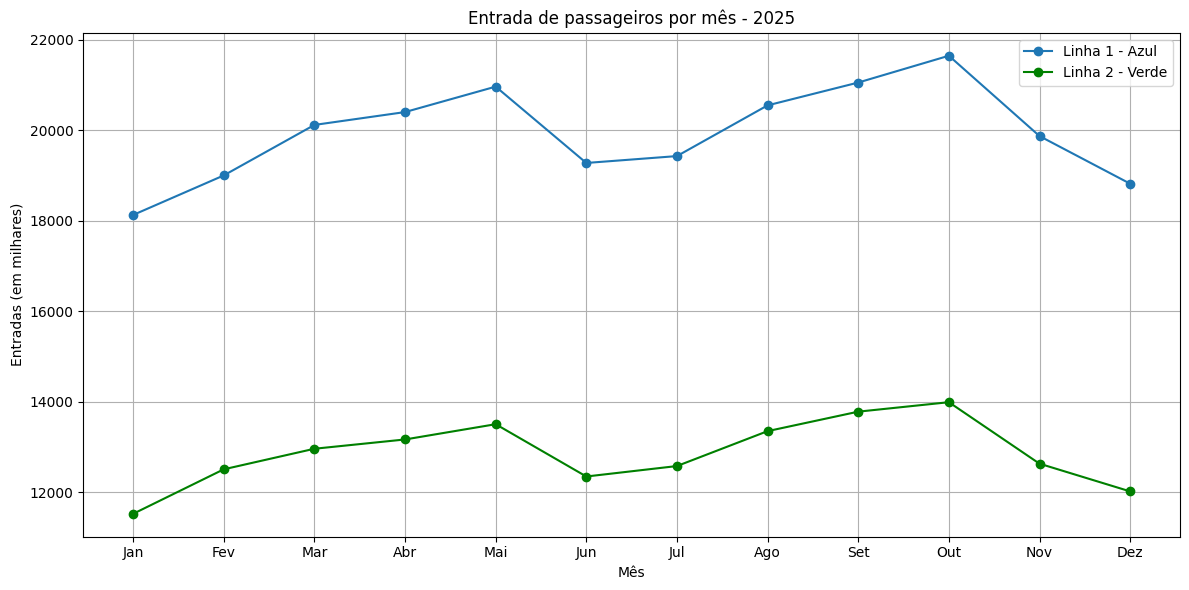

In [353]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(azul["Mês"], azul["Total"], marker="o", label="Linha 1 - Azul")
plt.plot(verde["Mês"], verde["Total"], marker="o", label="Linha 2 - Verde", color="green")

plt.title("Entrada de passageiros por mês - 2025")
plt.xlabel("Mês")
plt.ylabel("Entradas (em milhares)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [354]:
print("LINHA AZUL")
print(azul[["Mês", "Total"]].to_string(index=False))

print("\nLINHA VERDE")
print(verde[["Mês", "Total"]].to_string(index=False))

LINHA AZUL
Mês  Total
Jan  18128
Fev  19001
Mar  20116
Abr  20400
Mai  20962
Jun  19276
Jul  19428
Ago  20548
Set  21052
Out  21644
Nov  19870
Dez  18818

LINHA VERDE
Mês  Total
Jan  11528
Fev  12511
Mar  12965
Abr  13170
Mai  13507
Jun  12352
Jul  12583
Ago  13354
Set  13784
Out  13993
Nov  12635
Dez  12023


In [355]:

# Estatísticas descritivas das linhas Azul e Verde

print("Linha 1 - Azul")
print("Média:", azul["Total"].mean())
print("Mediana:", azul["Total"].median())
print("Maior demanda:", azul["Total"].max())
print("Menor demanda:", azul["Total"].min())

print("\nLinha 2 - Verde")
print("Média:", verde["Total"].mean())
print("Mediana:", verde["Total"].median())
print("Maior demanda:", verde["Total"].max())
print("Menor demanda:", verde["Total"].min())


Linha 1 - Azul
Média: 19936.916666666668
Mediana: 19993.0
Maior demanda: 21644
Menor demanda: 18128

Linha 2 - Verde
Média: 12867.083333333334
Mediana: 12800.0
Maior demanda: 13993
Menor demanda: 11528


## 5. Análise das estações com maior demanda

Nesta etapa, são examinados os dados de entradas por estação da Linha 1-Azul. O objetivo é identificar as estações com maior média de entradas, considerando os registros disponíveis no arquivo de 2025.

In [356]:
from google.colab import files
arquivos = files.upload()

Saving Entrada de Passageiros por Estação - Diária - 2025_7.csv to Entrada de Passageiros por Estação - Diária - 2025_7 (4).csv


In [357]:
import pandas as pd

df = pd.read_csv(list(arquivos.keys())[0], sep=";", encoding="latin1")
display(df.head())

,METRÔ DE SÃO PAULO,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 67,Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76
0,INFORMAÇÕES SOBRE A DEMANDA - 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Entrada de Passageiros por Estação - Diária (e...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JAN/20...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DIA,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,...,SLU,CAD,VTL,VUN,JPL,SAP,FJT,MAT,IGT,TOTAL


In [358]:
df = pd.read_csv(
    list(arquivos.keys())[0],
    sep=";",
    encoding="latin1",
    skiprows=4
)

display(df.head())

,ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JAN/2025 (MIL),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 67,Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76
0,DIA,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,...,SLU,CAD,VTL,VUN,JPL,SAP,FJT,MAT,IGT,TOTAL
1,1,"46,2","4,3","2,6","3,9","1,9","19,3","2,3","2,8",3,...,"0,8","0,6",1,1,"0,9","1,7","0,8","3,4","1,9","14,4"
2,2,"56,7","14,5","8,7","14,6","7,9",54,"8,5","10,1","10,1",...,"2,6","1,9","2,9","3,2","2,8","5,5","2,3","10,3","6,9",47
3,3,"57,7","15,2","9,6","16,7","9,2","60,3","9,6","11,5","11,4",...,"2,9","2,1","3,3","3,6",3,"5,9","2,6","11,7","7,6","52,4"
4,4,"43,3",10,"6,4","12,3","6,5","44,4","6,3","9,3","8,8",...,2,"1,4","2,4","2,5","2,3","4,3","1,8","7,8","4,4",35


In [359]:
df = pd.read_csv(
    list(arquivos.keys())[0],
    sep=";",
    encoding="latin1",
    skiprows=5,
    decimal=","
)

display(df.head())
print(df.shape)

,DIA,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,...,SLU,CAD,VTL,VUN,JPL,SAP,FJT,MAT,IGT,TOTAL.3
0,1,"46,2","4,3","2,6","3,9","1,9","19,3","2,3","2,8",3,...,"0,8","0,6",1,1,"0,9","1,7","0,8","3,4","1,9","14,4"
1,2,"56,7","14,5","8,7","14,6","7,9",54,"8,5","10,1","10,1",...,"2,6","1,9","2,9","3,2","2,8","5,5","2,3","10,3","6,9",47
2,3,"57,7","15,2","9,6","16,7","9,2","60,3","9,6","11,5","11,4",...,"2,9","2,1","3,3","3,6",3,"5,9","2,6","11,7","7,6","52,4"
3,4,"43,3",10,"6,4","12,3","6,5","44,4","6,3","9,3","8,8",...,2,"1,4","2,4","2,5","2,3","4,3","1,8","7,8","4,4",35
4,5,"37,3","6,6","4,2","7,4","3,6","28,2","3,9","5,8",5,...,"1,3","0,8","1,4","1,5","1,3","2,5","1,2","4,8","2,6","20,9"


(425, 77)


In [360]:
print(df.columns.tolist())
print(df.iloc[:, 0].tail(10))

['DIA', 'JAB', 'CON', 'JUD', 'SAU', 'ARV', 'SCZ', 'VMN', 'ANR', 'PSO', 'VGO', 'JQM', 'LIB', 'PSE', 'BTO', 'LUZ', 'TRD', 'PPQ', 'TTE', 'CDU', 'SAN', 'JPA', 'PIG', 'TUC', 'TOTAL', 'Unnamed: 25', 'DIA.1', 'VPT', 'TTI', 'SAC', 'AIP', 'IMG', 'CKB', 'ANR.1', 'PSO.1', 'BGD', 'TRI', 'CNS', 'CLI', 'SUM', 'VMD', 'TOTAL.1', 'Unnamed: 42', 'DIA.2', 'ITQ', 'ART', 'PCA', 'VPA', 'VTD', 'PEN', 'CAR', 'TAT', 'BEL', 'BRE', 'BAS', 'PDS', 'PSE.1', 'GBU', 'REP', 'CEC', 'DEO', 'BFU', 'TOTAL.2', 'Unnamed: 63', 'DIA.3', ' VPM ', ' ORT ', ' SLU ', ' CAD ', ' VTL ', ' VUN ', ' JPL ', ' SAP ', ' FJT ', ' MAT ', 'IGT', 'TOTAL.3']
415                                                   28
416                                                   29
417                                                   30
418                                                   31
419                                                Total
420                                                  NaN
421    ¹ Corresponde às entradas pelas linhas de

In [361]:
# Localizar onde começam os blocos de cada linha
for i in range(len(df)):
    valor = str(df.iloc[i, 0])
    if "ENTRADAS POR ESTAÇÃO" in valor:
        print(i, valor)

34 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - FEV/2025 (MIL)
70 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - MAR/2025 (MIL)
106 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - ABR/2025 (MIL)
141 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - MAI/2025 (MIL)
176 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JUN/2025 (MIL)
211 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JUL/2025 (MIL)
246 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - AGO/2025 (MIL)
281 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - SET/2025 (MIL)
316 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - OUT/2025 (MIL)
351 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - NOV/2025 (MIL)
386 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - DEZ/2025 (MIL)


In [362]:
# Selecionar as linhas com os dias do mês e excluir totais
azul = df.iloc[:, 0:25].copy()
azul = azul[azul["DIA"].astype(str).str.strip().str.isdigit()].copy()

# Converter os valores para números
for coluna in azul.columns[1:]:
    azul[coluna] = pd.to_numeric(azul[coluna], errors="coerce")

# Mostrar as estações com maior demanda média
medias = azul.drop(columns=["DIA", "TOTAL"]).mean().sort_values(ascending=False)

display(medias.head(10))

,0
LUZ,100.285714
SCZ,70.866667
JAB,58.256410
TUC,44.411765
SAN,38.147059
BTO,37.972222
TTE,37.611111
JQM,25.000000
CON,24.810811
SAU,22.548387


In [363]:
for i in range(len(df)):
    valor = str(df.iloc[i, 0])
    if "ENTRADAS POR ESTAÇÃO" in valor:
        print(i, valor)

34 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - FEV/2025 (MIL)
70 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - MAR/2025 (MIL)
106 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - ABR/2025 (MIL)
141 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - MAI/2025 (MIL)
176 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JUN/2025 (MIL)
211 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - JUL/2025 (MIL)
246 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - AGO/2025 (MIL)
281 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - SET/2025 (MIL)
316 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - OUT/2025 (MIL)
351 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - NOV/2025 (MIL)
386 ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL ¹ - DEZ/2025 (MIL)


In [364]:
import pandas as pd

arquivo = list(arquivos.keys())[0]

# Ler o arquivo sem alterar os dados originais
bruto = pd.read_csv(arquivo, sep=";", encoding="latin1", header=None)

# Identificar os blocos mensais da Linha Azul
resultados = []

for i in range(len(bruto)):
    titulo = str(bruto.iloc[i, 0])

    if "ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL" in titulo:
        cabecalho = i + 1
        dados = bruto.iloc[cabecalho + 1:cabecalho + 32, :25].copy()
        dados.columns = bruto.iloc[cabecalho, :25].astype(str).str.strip()

        dados = dados[dados["DIA"].astype(str).str.strip().str.isdigit()]

        for coluna in dados.columns[1:]:
            dados[coluna] = pd.to_numeric(
                dados[coluna].astype(str).str.replace(",", ".", regex=False),
                errors="coerce"
            )

        resultados.append(dados.drop(columns=["DIA", "TOTAL"], errors="ignore"))

# Calcular a média das entradas por estação
anual = pd.concat(resultados, ignore_index=True)
medias = anual.mean().sort_values(ascending=False)

display(medias.head(10))

,0
LUZ,101.536164
SCZ,76.003014
JAB,58.304658
TUC,45.949176
BTO,40.863836
SAN,40.031507
TTE,38.297534
JQM,24.286264
CON,23.007397
LIB,22.282192


## 6. Visualização das dez estações com maior demanda

O gráfico de barras horizontais apresenta as dez estações da Linha 1-Azul com maior média de entradas. A visualização facilita a comparação entre as estações e destaca aquelas com maior movimentação de passageiros.

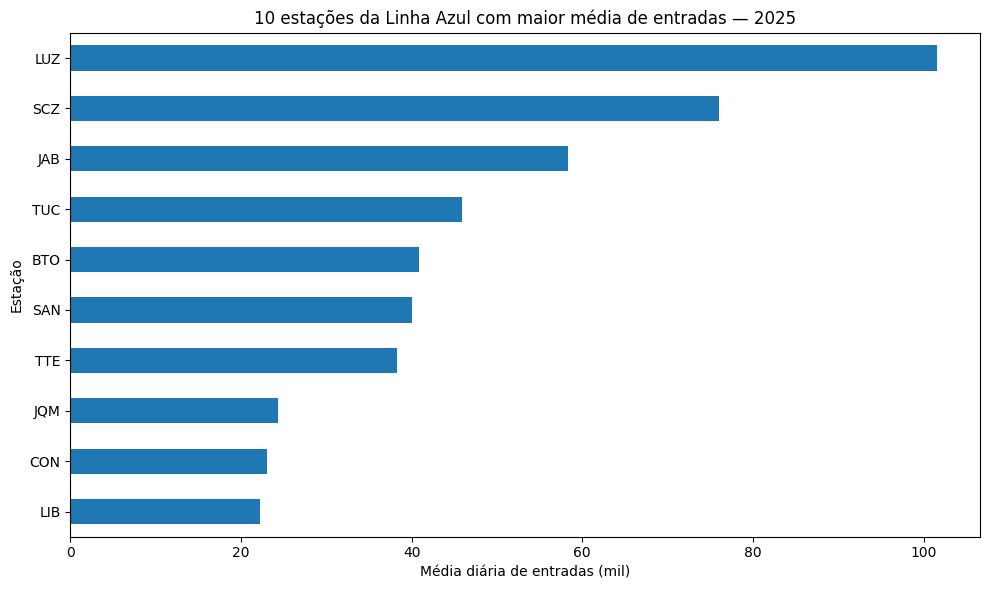

In [365]:
import matplotlib.pyplot as plt

top10 = medias.head(10).sort_values()

plt.figure(figsize=(10, 6))
top10.plot(kind="barh")
plt.title("10 estações da Linha Azul com maior média de entradas — 2025")
plt.xlabel("Média diária de entradas (mil)")
plt.ylabel("Estação")
plt.tight_layout()
plt.show()

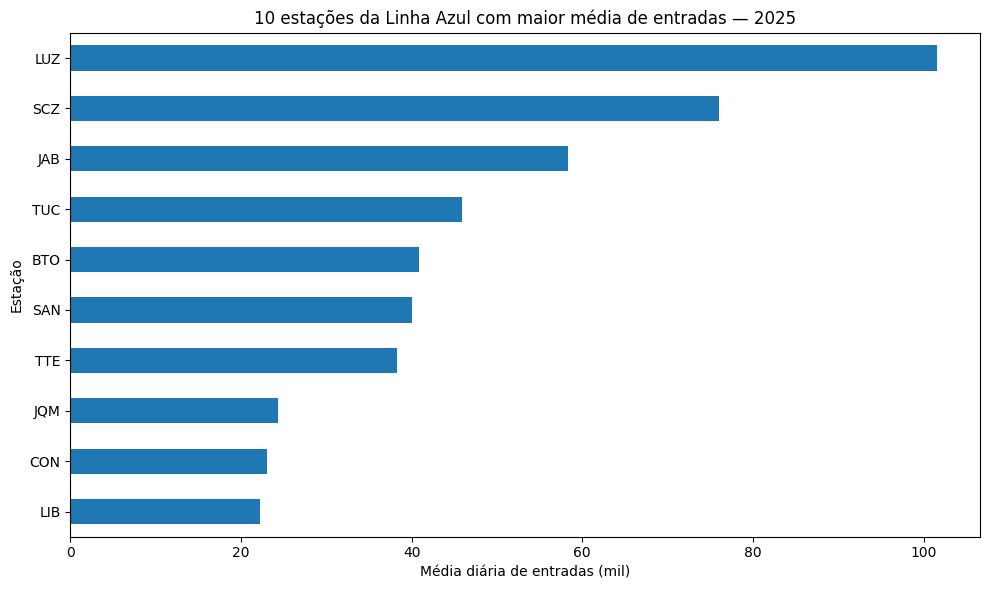

In [366]:
plt.figure(figsize=(10, 6))
top10.plot(kind="barh")
plt.title("10 estações da Linha Azul com maior média de entradas — 2025")
plt.xlabel("Média diária de entradas (mil)")
plt.ylabel("Estação")
plt.tight_layout()
plt.savefig("grafico_top10_linha_azul.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Variação mensal da demanda da Linha Azul

Nesta etapa, é calculada a média diária de entradas para cada mês. O gráfico permite observar como a demanda varia ao longo do ano, considerando os dados mensais disponíveis.

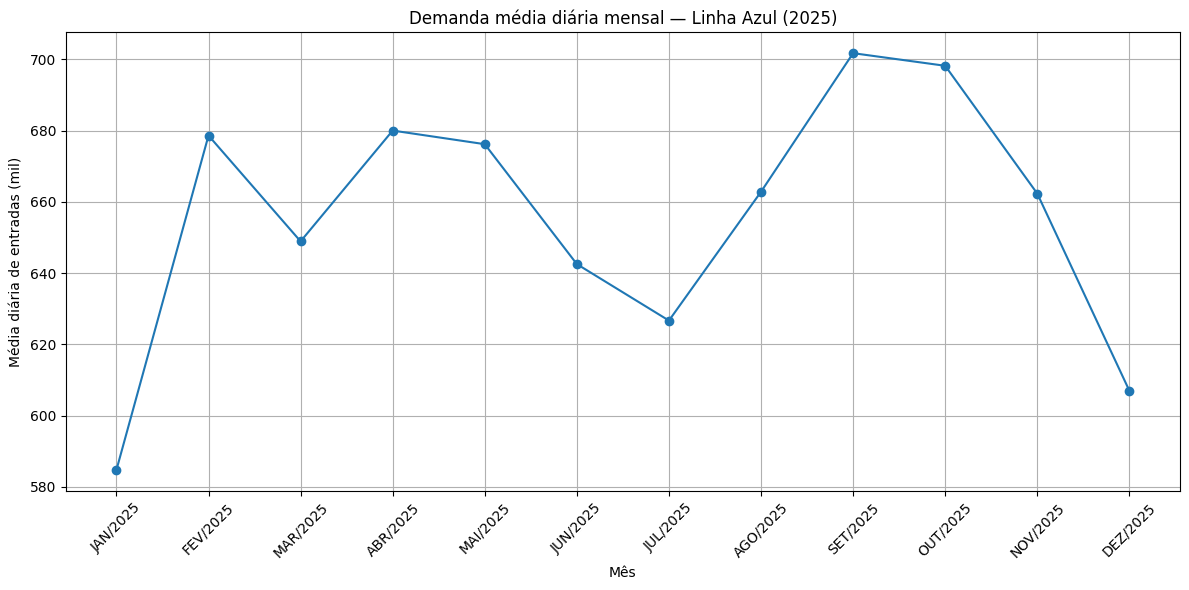

In [367]:
import matplotlib.pyplot as plt

meses = []
demandas = []

for i in range(len(bruto)):
    titulo = str(bruto.iloc[i, 0])

    if "ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL" in titulo:
        cabecalho = i + 1
        dados_mes = bruto.iloc[cabecalho + 1:cabecalho + 32, :25].copy()
        dados_mes.columns = bruto.iloc[cabecalho, :25].astype(str).str.strip()

        dias = dados_mes["DIA"].astype(str).str.strip().str.isdigit()
        dados_mes = dados_mes[dias]

        total = pd.to_numeric(
            dados_mes["TOTAL"].astype(str).str.replace(",", ".", regex=False),
            errors="coerce"
        )

        meses.append(titulo.split(" - ")[-1].replace(" (MIL)", ""))
        demandas.append(total.mean())

plt.figure(figsize=(12, 6))
plt.plot(meses, demandas, marker="o")
plt.title("Demanda média diária mensal — Linha Azul (2025)")
plt.xlabel("Mês")
plt.ylabel("Média diária de entradas (mil)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### 7.1. Comparação mensal das cinco estações mais movimentadas

A análise compara a média diária de entradas nas cinco estações com maior demanda. O objetivo é observar se as estações apresentam padrões mensais semelhantes ou diferenças de movimentação ao longo do ano.

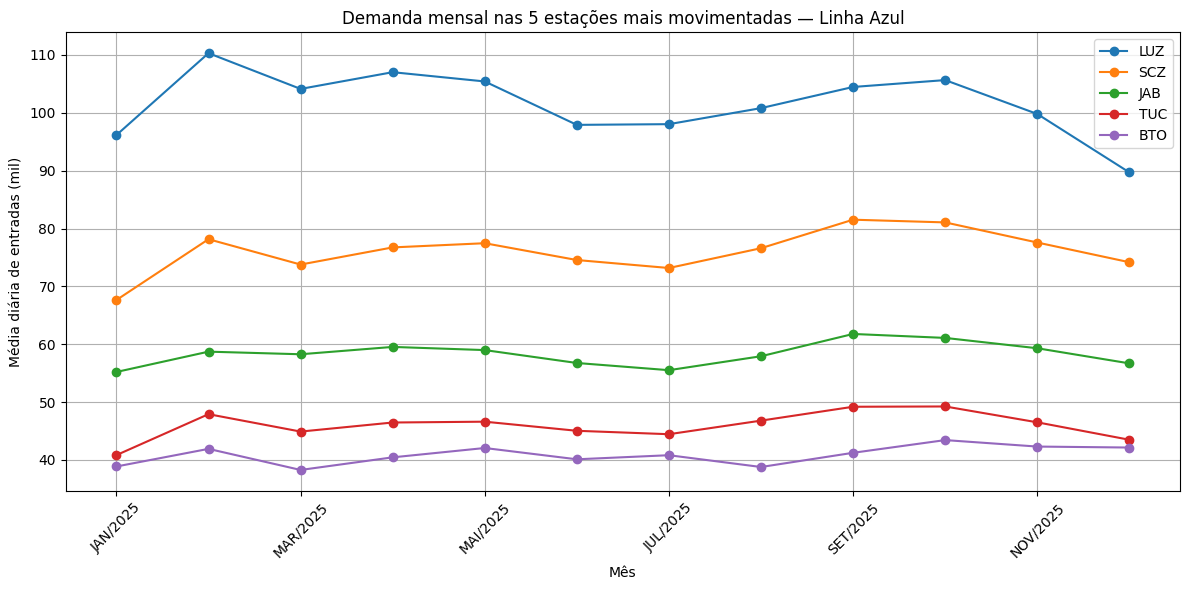

In [368]:
# Média mensal de entradas nas 5 estações mais movimentadas
estacoes = medias.head(5).index.tolist()
dados_mensais = []

for i in range(len(bruto)):
    titulo = str(bruto.iloc[i, 0])

    if "ENTRADAS POR ESTAÇÃO - LINHA 1-AZUL" in titulo:
        cabecalho = i + 1
        dados_mes = bruto.iloc[cabecalho + 1:cabecalho + 32, :25].copy()
        dados_mes.columns = bruto.iloc[cabecalho, :25].astype(str).str.strip()
        dados_mes = dados_mes[
            dados_mes["DIA"].astype(str).str.strip().str.isdigit()
        ]

        linha = {"Mês": titulo.split(" - ")[-1].replace(" (MIL)", "")}

        for estacao in estacoes:
            linha[estacao] = pd.to_numeric(
                dados_mes[estacao].astype(str).str.replace(",", ".", regex=False),
                errors="coerce"
            ).mean()

        dados_mensais.append(linha)

mensal = pd.DataFrame(dados_mensais).set_index("Mês")

mensal.plot(figsize=(12, 6), marker="o")
plt.title("Demanda mensal nas 5 estações mais movimentadas — Linha Azul")
plt.xlabel("Mês")
plt.ylabel("Média diária de entradas (mil)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [369]:
mensal.to_csv("demanda_mensal_top5_linha_azul.csv", encoding="utf-8-sig")

from google.colab import files
files.download("demanda_mensal_top5_linha_azul.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Análise da oferta de trens

Nesta etapa, é carregado o conjunto de dados referente aos intervalos mínimos entre trens. As informações são exploradas e organizadas para permitir a comparação entre as linhas metroviárias durante 2026.

In [370]:
from google.colab import files
arquivos_oferta = files.upload()

Saving Oferta - 2026_4.csv to Oferta - 2026_4 (3).csv


In [371]:
import pandas as pd

arquivo_oferta = list(arquivos_oferta.keys())[0]

oferta = pd.read_csv(
    arquivo_oferta,
    sep=";",
    encoding="latin1"
)

display(oferta.head())
print(oferta.shape)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,METRÔ DE SÃO PAULO,NaN,NaN,NaN,NaN
1,INFORMAÇÕES SOBRE A OFERTA - 2026,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,Intervalo mínimo entre trens (segundos),NaN,NaN,NaN,NaN
4,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata


(36, 5)


In [372]:
oferta = pd.read_csv(
    arquivo_oferta,
    sep=";",
    encoding="latin1",
    skiprows=4
)

display(oferta.head(10))

,Intervalo mínimo entre trens (segundos),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
1,Jan,132,131,132,171
2,Fev,132,131,132,170
3,Mar,132,131,132,170
4,Abr,131,131,132,170
5,Mai,131,131,132,170
6,Jun,131,118,132,170
7,Jul,131,127,132,170
8,Ago,NaN,NaN,NaN,NaN
9,Set,NaN,NaN,NaN,NaN


In [373]:
print("Colunas da tabela oferta:")
print(oferta.columns.tolist())

print("\nPrimeiras linhas:")
display(oferta.head(10))

Colunas da tabela oferta:
['Intervalo mínimo entre trens (segundos)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Primeiras linhas:


,Intervalo mínimo entre trens (segundos),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
1,Jan,132,131,132,171
2,Fev,132,131,132,170
3,Mar,132,131,132,170
4,Abr,131,131,132,170
5,Mai,131,131,132,170
6,Jun,131,118,132,170
7,Jul,131,127,132,170
8,Ago,NaN,NaN,NaN,NaN
9,Set,NaN,NaN,NaN,NaN


In [374]:
oferta.columns = oferta.columns.str.strip()

In [375]:
oferta.columns = oferta.columns.str.strip()

print(oferta.columns.tolist())

['Intervalo mínimo entre trens (segundos)', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [376]:
print(oferta.head(3))
print("\nFormato da tabela:", oferta.shape)

  Intervalo mínimo entre trens (segundos)     Unnamed: 1     Unnamed: 2  \
0                                     Mês  Linha 1-Azul   Linha 2-Verde   
1                                     Jan            132            131   
2                                     Fev            132            131   

         Unnamed: 3       Unnamed: 4  
0  Linha 3-Vermelha  Linha 15-Prata   
1               132              171  
2               132              170  

Formato da tabela: (32, 5)


In [377]:
oferta.columns = [
    "Mês",
    "Linha 1-Azul",
    "Linha 2-Verde",
    "Linha 3-Vermelha",
    "Linha 15-Prata"
]

print(oferta.columns.tolist())
display(oferta.head(3))

['Mês', 'Linha 1-Azul', 'Linha 2-Verde', 'Linha 3-Vermelha', 'Linha 15-Prata']


,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
0,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
1,Jan,132,131,132,171
2,Fev,132,131,132,170


In [378]:
print(oferta.columns.tolist())

['Mês', 'Linha 1-Azul', 'Linha 2-Verde', 'Linha 3-Vermelha', 'Linha 15-Prata']


In [379]:
oferta_bruta = pd.read_csv(
    arquivo_oferta,
    sep=";",
    encoding="latin1",
    header=None
)

display(oferta_bruta.iloc[:12, :])

,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,METRÔ DE SÃO PAULO,NaN,NaN,NaN,NaN
2,INFORMAÇÕES SOBRE A OFERTA - 2026,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,Intervalo mínimo entre trens (segundos),NaN,NaN,NaN,NaN
5,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
6,Jan,132,131,132,171
7,Fev,132,131,132,170
8,Mar,132,131,132,170
9,Abr,131,131,132,170


In [380]:
display(oferta_bruta.iloc[5:20, :5])

,0,1,2,3,4
5,Mês,Linha 1-Azul,Linha 2-Verde,Linha 3-Vermelha,Linha 15-Prata
6,Jan,132,131,132,171
7,Fev,132,131,132,170
8,Mar,132,131,132,170
9,Abr,131,131,132,170
10,Mai,131,131,132,170
11,Jun,131,118,132,170
12,Jul,131,127,132,170
13,Ago,NaN,NaN,NaN,NaN
14,Set,NaN,NaN,NaN,NaN


### 8.1. Comparação dos intervalos entre trens

O gráfico compara os intervalos mínimos entre trens das Linhas 1-Azul, 2-Verde, 3-Vermelha e 15-Prata ao longo dos meses de 2026. A análise permite identificar diferenças na oferta programada entre as linhas.

<Figure size 1200x500 with 0 Axes>

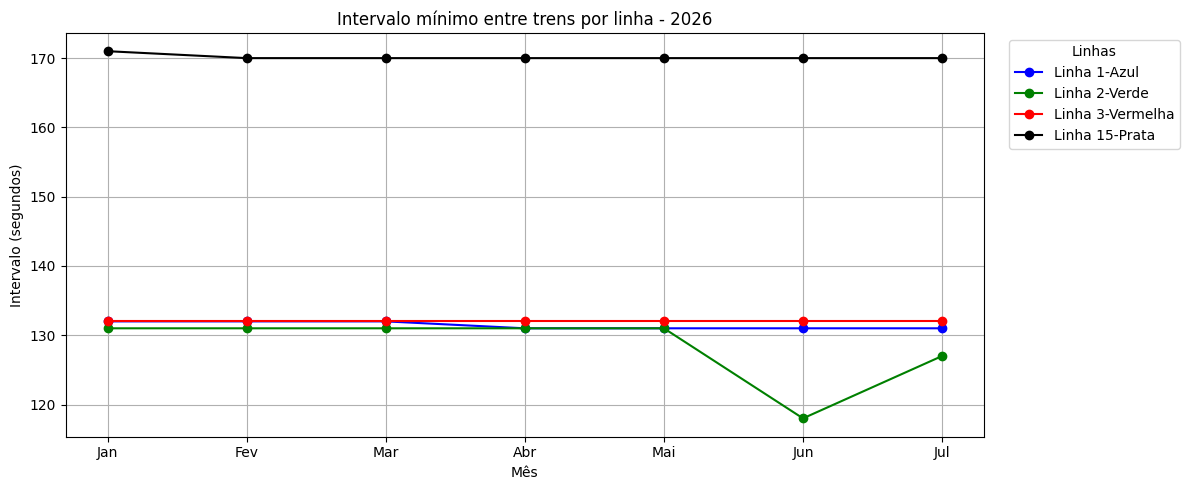

In [381]:
plt.figure(figsize=(12, 5))

oferta_grafico.plot(
    x="Mês",
    y=["Linha 1-Azul", "Linha 2-Verde", "Linha 3-Vermelha", "Linha 15-Prata"],
    color=["blue", "green", "red", "black"],
    marker="o",
    figsize=(12, 5)
)

plt.title("Intervalo mínimo entre trens por linha - 2026")
plt.xlabel("Mês")
plt.ylabel("Intervalo (segundos)")
plt.grid(True)

plt.legend(
    title="Linhas",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [382]:
display(df.iloc[3:12, 0:6])

,DIA,JAB,CON,JUD,SAU,ARV
3,4,"43,3",10,"6,4","12,3","6,5"
4,5,"37,3","6,6","4,2","7,4","3,6"
5,6,"62,4","24,6","12,4","21,1","11,9"
6,7,"60,2","25,8","12,9","21,6","12,6"
7,8,"60,2","26,3","13,4","25,4",13
8,9,"59,9","25,6","13,5","22,8",13
9,10,"60,2","22,2","13,3","22,4","13,3"
10,11,"43,1","12,3","7,8",15,"8,2"
11,12,"33,6","7,6","4,5","8,3","4,3"


In [383]:
print(azul.head())
print(verde.head())

  DIA  JAB   CON  JUD  SAU  ARV   SCZ  VMN  ANR  PSO  ...  LUZ  TRD  PPQ  \
0   1  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  3.0  ...  NaN  NaN  NaN   
1   2  NaN   NaN  NaN  NaN  NaN  54.0  NaN  NaN  NaN  ...  NaN  NaN  NaN   
2   3  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  NaN  ...  NaN  7.0  NaN   
3   4  NaN  10.0  NaN  NaN  NaN   NaN  NaN  NaN  NaN  ...  NaN  NaN  NaN   
4   5  NaN   NaN  NaN  NaN  NaN   NaN  NaN  NaN  5.0  ...  NaN  NaN  NaN   

    TTE  CDU   SAN  JPA  PIG  TUC  TOTAL  
0  27.0  NaN   NaN  NaN  NaN  NaN    NaN  
1   NaN  NaN   NaN  NaN  NaN  NaN    NaN  
2   NaN  NaN   NaN  NaN  NaN  NaN    NaN  
3   NaN  NaN  21.0  NaN  NaN  NaN  392.0  
4   NaN  NaN   NaN  NaN  NaN  NaN    NaN  

[5 rows x 25 columns]
   Mês  Total  MDU  MSA  MDO  MAX
5  Jan  11528  455  218  144  506
6  Fev  12511  542  260  156  584
7  Mar  12965  556  262  164  581
8  Abr  13170  561  245  158  585
9  Mai  13507  555  248  155  581


In [384]:
print("AZUL — tabela mensal:")
display(azul)

print("VERDE — tabela mensal:")
display(verde)

AZUL — tabela mensal:


,DIA,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,...,LUZ,TRD,PPQ,TTE,CDU,SAN,JPA,PIG,TUC,TOTAL
0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,...,NaN,NaN,NaN,27.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2,NaN,NaN,NaN,NaN,NaN,54.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,NaN,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,21.0,NaN,NaN,NaN,392.0
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414,27,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
415,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN
416,29,NaN,NaN,NaN,NaN,9.0,NaN,NaN,NaN,NaN,...,71.0,NaN,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
417,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,29.0,NaN,NaN,NaN,NaN


VERDE — tabela mensal:


,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,11528,455,218,144,506
6,Fev,12511,542,260,156,584
7,Mar,12965,556,262,164,581
8,Abr,13170,561,245,158,585
9,Mai,13507,555,248,155,581
10,Jun,12352,528,248,159,564
11,Jul,12583,491,243,151,517
12,Ago,13354,540,249,154,576
13,Set,13784,547,253,183,570
14,Out,13993,540,242,153,564


## 9. Consolidação e interpretação dos resultados

Nesta etapa, são reunidos os principais indicadores calculados nas análises anteriores. A comparação entre as médias mensais das Linhas Azul e Verde permite avaliar diferenças de demanda, enquanto os resultados por estação destacam os pontos de maior movimentação. Os intervalos entre trens complementam a análise da oferta do sistema.

In [385]:
print(azul.columns.tolist())
print(verde.columns.tolist())

['DIA', 'JAB', 'CON', 'JUD', 'SAU', 'ARV', 'SCZ', 'VMN', 'ANR', 'PSO', 'VGO', 'JQM', 'LIB', 'PSE', 'BTO', 'LUZ', 'TRD', 'PPQ', 'TTE', 'CDU', 'SAN', 'JPA', 'PIG', 'TUC', 'TOTAL']
['Mês', 'Total', 'MDU', 'MSA', 'MDO', 'MAX']


In [397]:
print("Azul:", azul.columns.tolist())
print("Verde:", verde.columns.tolist())
print("df_linhas:", df_linhas.shape)

Azul: ['DIA', 'JAB', 'CON', 'JUD', 'SAU', 'ARV', 'SCZ', 'VMN', 'ANR', 'PSO', 'VGO', 'JQM', 'LIB', 'PSE', 'BTO', 'LUZ', 'TRD', 'PPQ', 'TTE', 'CDU', 'SAN', 'JPA', 'PIG', 'TUC', 'TOTAL']
Verde: ['Mês', 'Total', 'MDU', 'MSA', 'MDO', 'MAX']
df_linhas: (58, 13)


In [399]:

print("ANÁLISE DA DEMANDA DE PASSAGEIROS — 2025")

# Recuperar as tabelas mensais da seção 3
azul_mensal = df_linhas.iloc[5:17, 0:6].copy()
azul_mensal.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

verde_mensal = df_linhas.iloc[5:17, 7:13].copy()
verde_mensal.columns = ["Mês", "Total", "MDU", "MSA", "MDO", "MAX"]

for tabela in [azul_mensal, verde_mensal]:
    tabela["Mês"] = tabela["Mês"].astype(str).str.strip()
    tabela["Total"] = (
        tabela["Total"].astype(str)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    tabela["Total"] = pd.to_numeric(tabela["Total"], errors="coerce")

print(f"Média mensal da Linha Azul: {azul_mensal['Total'].mean():,.2f}")
print(f"Média mensal da Linha Verde: {verde_mensal['Total'].mean():,.2f}")

print(f"\nMês de maior demanda da Linha Azul: {azul_mensal.loc[azul_mensal['Total'].idxmax(), 'Mês']}")
print(f"Mês de menor demanda da Linha Azul: {azul_mensal.loc[azul_mensal['Total'].idxmin(), 'Mês']}")

print(f"\nMês de maior demanda da Linha Verde: {verde_mensal.loc[verde_mensal['Total'].idxmax(), 'Mês']}")
print(f"Mês de menor demanda da Linha Verde: {verde_mensal.loc[verde_mensal['Total'].idxmin(), 'Mês']}")

media_azul = azul_mensal["Total"].mean()
media_verde = verde_mensal["Total"].mean()

diferenca = media_azul - media_verde
percentual = (diferenca / media_verde) * 100

print(f"Diferença entre as médias: {diferenca:,.2f}")
print(f"A demanda média da Linha Azul foi {percentual:.2f}% maior que a da Linha Verde.")


ANÁLISE DA DEMANDA DE PASSAGEIROS — 2025
Média mensal da Linha Azul: 19,936.92
Média mensal da Linha Verde: 12,867.08

Mês de maior demanda da Linha Azul: Out
Mês de menor demanda da Linha Azul: Jan

Mês de maior demanda da Linha Verde: Out
Mês de menor demanda da Linha Verde: Jan
Diferença entre as médias: 7,069.83
A demanda média da Linha Azul foi 54.95% maior que a da Linha Verde.


In [401]:
media_azul = azul_mensal["Total"].mean()
media_verde = verde_mensal["Total"].mean()

diferenca = media_azul - media_verde
percentual = (diferenca / media_verde) * 100

print(f"Diferença entre as médias: {diferenca:,.2f}")
print(f"A demanda média da Linha Azul foi {percentual:.2f}% maior que a da Linha Verde.")

Diferença entre as médias: 7,069.83
A demanda média da Linha Azul foi 54.95% maior que a da Linha Verde.


In [390]:
[v for v in globals() if isinstance(globals()[v], __import__('pandas').DataFrame)]

['_',
 '__',
 'df',
 '_5',
 '_6',
 '_8',
 '_12',
 'azul',
 'verde',
 '_16',
 '_23',
 'azul_grafico',
 'verde_grafico',
 'tabela',
 'janeiro',
 'bruto',
 'dados',
 'anual',
 'dados_mes',
 'mensal',
 'oferta',
 'oferta_grafico',
 'oferta_bruta',
 'evolucao',
 'df_linhas',
 'top10_azul',
 '_127',
 '_131',
 '_135',
 '_193',
 '_197',
 '_201',
 '_204',
 '_208',
 '_212',
 'azul_estacoes',
 '_297',
 '_301',
 '_305',
 '_309',
 '_313',
 '_317',
 '_322',
 '_326',
 '_330']

In [389]:
print("DADOS:")
display(dados.head())

print("TABELA:")
display(tabela.head())

print("ANUAL:")
display(anual.head())

DADOS:


393,DIA,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,...,LUZ,TRD,PPQ,TTE,CDU,SAN,JPA,PIG,TUC,TOTAL
394,1,72.2,30.2,15.2,26.0,15.3,94.6,17.6,20.2,20.6,...,123.2,15.1,19.3,46.6,11.3,48.8,11.6,13.3,57.3,809.4
395,2,70.4,32.8,16.3,27.3,16.5,100.6,19.8,22.5,21.8,...,123.2,15.8,19.3,41.9,11.9,51.0,12.5,13.8,59.9,834.0
396,3,74.1,32.5,16.2,27.8,16.7,99.0,19.8,22.2,21.8,...,147.4,15.6,19.3,41.3,12.2,51.3,12.4,14.0,60.2,862.2
397,4,78.0,31.3,16.6,27.8,16.9,99.4,20.3,22.4,22.2,...,128.2,15.6,18.9,43.0,12.1,51.1,12.4,14.0,60.3,847.3
398,5,81.3,28.4,16.5,27.7,16.7,101.1,19.9,21.9,21.3,...,145.7,15.7,19.1,47.3,11.8,51.1,12.0,13.3,60.2,867.7


TABELA:


,Mês,Total,MDU,MSA,MDO,MAX
5,Jan,11528,455,218,144,506
6,Fev,12511,542,260,156,584
7,Mar,12965,556,262,164,581
8,Abr,13170,561,245,158,585
9,Mai,13507,555,248,155,581


ANUAL:


,JAB,CON,JUD,SAU,ARV,SCZ,VMN,ANR,PSO,VGO,...,BTO,LUZ,TRD,PPQ,TTE,CDU,SAN,JPA,PIG,TUC
0,46.2,4.3,2.6,3.9,1.9,19.3,2.3,2.8,3.0,4.3,...,2.9,14.7,1.9,3.7,27.0,1.5,8.4,1.4,1.8,10.2
1,56.7,14.5,8.7,14.6,7.9,54.0,8.5,10.1,10.1,14.3,...,34.0,71.7,6.1,10.9,46.9,5.6,27.2,5.1,6.1,32.5
2,57.7,15.2,9.6,16.7,9.2,60.3,9.6,11.5,11.4,16.0,...,40.2,84.6,7.0,11.8,41.3,6.4,30.4,5.8,6.9,36.5
3,43.3,10.0,6.4,12.3,6.5,44.4,6.3,9.3,8.8,10.0,...,28.0,57.2,5.5,8.1,34.7,3.8,21.0,3.9,4.4,25.2
4,37.3,6.6,4.2,7.4,3.6,28.2,3.9,5.8,5.0,6.5,...,5.7,25.2,3.2,5.1,34.6,2.8,12.8,2.3,2.8,15.9


In [388]:
top10_azul = (
    anual.mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top10_azul.columns = ["Estação", "Média de entradas"]

display(top10_azul)

,Estação,Média de entradas
0,LUZ,101.536164
1,SCZ,76.003014
2,JAB,58.304658
3,TUC,45.949176
4,BTO,40.863836
5,SAN,40.031507
6,TTE,38.297534
7,JQM,24.286264
8,CON,23.007397
9,LIB,22.282192


### 9.1. Intervalo médio entre trens

São apresentados os intervalos médios de cada linha com base nos dados carregados. Esses valores ajudam a comparar a oferta registrada entre as linhas analisadas.

In [387]:
print("INTERVALO MÉDIO ENTRE TRENS — 2026")

display(oferta_grafico.drop(columns=["Mês"]).mean().round(2))

INTERVALO MÉDIO ENTRE TRENS — 2026


,0
Linha 1-Azul,131.43
Linha 2-Verde,128.57
Linha 3-Vermelha,132.00
Linha 15-Prata,170.14


## 10. Conclusão

A análise dos dados públicos permitiu observar diferenças na demanda de passageiros entre as Linhas 1-Azul e 2-Verde, identificar as estações mais movimentadas da Linha Azul e comparar os intervalos mínimos entre trens de diferentes linhas.

Essas informações podem contribuir para o planejamento operacional e para a identificação de períodos e locais que merecem maior atenção. Entretanto, os dados analisados não são suficientes, por si só, para determinar quando uma manutenção deve ser realizada.

Para avançar no planejamento de manutenções, seria necessário integrar informações sobre falhas, interrupções, histórico de manutenção e condições da infraestrutura. Também é importante considerar que os conjuntos de dados analisados correspondem a períodos diferentes.